# Human fibroblast/decidual pseudotime

Standalone. Run top to bottom.

**Never plots a carried embedding.** The deliverable's `X_umap_scVI` is (or was) a row-subset
of the whole-tissue fit — that is what looked wrong last run. This notebook computes its own
UMAP on the 47,533 fib/dec cells and plots `basis="X_umap"`. There is a guard cell that fails
loudly if anything tries to plot a carried embedding.

Pipeline: 04b stromal latent → neighbors → UMAP → moscot `TemporalProblem` → CellRank
`RealTimeKernel` (with the row-stochasticity repair) → DPT.

**Human is structurally weak** and you should know this before reading the output: 2 timepoints
= 1 moscot transition, and `cell_subtype` is fully coarse-filled so there is no fine label to
anchor the root on. The headless run gave ρ(pt, day) = **+0.077** (medians 0.4497 → 0.4509).
Mouse, for contrast, gave +0.6654 with 5 transitions and an `efib_proliferative` anchor.

## Setup

In [1]:
import os, json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, issparse
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import anndata as ad
import cellrank as cr
from scanpy.tools._dpt import DPT
import jax

from gpu_utils import *

REPO = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final")
DATE = "2026_08_28"
VARIANT = "v1_all_cells"

ADATA_PATH = REPO / f"data/deliverables/{DATE}_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"
LATENT_04B = REPO / "data/interim/latent_human_stromal.h5ad"

OUT = Path(f"./pseudotime_human/{VARIANT}")
FIG = OUT / "figures"; RES = OUT / "results"
FIG.mkdir(parents=True, exist_ok=True); RES.mkdir(parents=True, exist_ok=True)

SEED = 0
np.random.seed(SEED)
sc.settings.verbosity = 2
cr.settings.verbosity = 2

def savefig(name):
    p = FIG / f"{name}.pdf"
    plt.savefig(p, bbox_inches="tight", dpi=300)
    print(f"  saved {p}")

print("input :", ADATA_PATH)
print("latent:", LATENT_04B)
print("jax   :", jax.default_backend(), jax.devices())
assert ADATA_PATH.is_file(), ADATA_PATH
assert jax.default_backend() == "gpu", "moscot needs JAX on GPU — get a GPU node"

gpu_utils: rapids-singlecell loaded. GPU acceleration enabled
input : /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/deliverables/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
latent: /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim/latent_human_stromal.h5ad


2026-08-28 23:49:26 | [INFO] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


jax   : gpu [CudaDevice(id=0)]


## Load

In [2]:
adata = sc.read_h5ad(ADATA_PATH)
print(adata)

assert adata.n_obs == 47533, f"expected 47,533 fib/dec cells, got {adata.n_obs:,}"
assert "counts" in adata.layers, f"no counts layer: {list(adata.layers)}"

print("\ncell_type:");    print(adata.obs["cell_type"].value_counts().to_string())
print("\ncell_subtype:"); print(adata.obs["cell_subtype"].value_counts().to_string())
print("\ntimepoint:");    print(adata.obs["timepoint"].value_counts().to_string())
print("\nobsm:", list(adata.obsm))

AnnData object with n_obs × n_vars = 47533 × 36601
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'lineage', 'cell_type', 'subtype', 'annotation_level', 'x_um_dbscan', 'y_um_dbscan', 'cell_subtype', 'stro7_margin'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'annotation_level_colors', 'annotation_schema_version', 'display_names', 'hvg', 'label_colors', 'log1p', 'neighbors_scVI_100', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_spatial', 'X_umap_scVI'
    layers: 'counts'

cell_type:
cell_type
endometrial_fibroblast    25885
decidual_cell             21648

cell_subtype:
cell_subtype
endometrial_fibroblast    25885
decidual_cell             21648

timepoint:
timepoint
menstrual    24092
secretory    23441

obsm: ['X_scVI', 'X_spatial', 'X_umap_scVI']


### Guard: drop every carried embedding

The bug that wasted the last run was plotting `X_umap_scVI`, which on this object is a
row-subset of the 66,830-cell whole-tissue UMAP. A UMAP is a property of the cell set it was
fit on — slicing rows out of one gives a layout shaped by 19,297 cells that are no longer here.

So we delete them from the in-memory object. Nothing can accidentally plot them, and the file
on disk is untouched.

In [3]:
CARRIED = [k for k in list(adata.obsm) if k not in ("X_spatial",)]
print("carried embeddings found:", CARRIED)

for k in CARRIED:
    del adata.obsm[k]
print("obsm after purge:", list(adata.obsm))

# X_scVI and X_umap are rebuilt below from the stromal-lineage fit.
assert "X_umap_scVI" not in adata.obsm
assert "X_umap" not in adata.obsm

carried embeddings found: ['X_scVI', 'X_umap_scVI']
obsm after purge: ['X_spatial']


## scVI latent: 04b's stromal-lineage fit

`04b_reintegrate` fit scVI on the stromal lineage with HVGs reselected on that subset — the
right embedding for within-stromal structure. 48,004 cells, a superset of this object's 47,533
(the extra 471 are the perivascular cells the v2 vocabulary reassigned out of stromal), so we
subset it by `obs_names`.

In [4]:
lat = sc.read_h5ad(LATENT_04B, backed="r")
lat_names = pd.Index(lat.obs_names.astype(str))
our_names = pd.Index(adata.obs_names.astype(str))

missing = int((~our_names.isin(lat_names)).sum())
print(f"04b latent: {lat.n_obs:,} cells | this object: {adata.n_obs:,} | missing: {missing}")
assert missing == 0, f"{missing} cells absent from the 04b latent"

idx = lat_names.get_indexer(our_names)
adata.obsm["X_scVI"] = np.asarray(lat.obsm["X_scVI"])[idx]
lat.file.close()

print(f"X_scVI: {adata.obsm['X_scVI'].shape}  (04b stromal fit, joined on obs_names)")

04b latent: 48,004 cells | this object: 47,533 | missing: 0
X_scVI: (47533, 30)  (04b stromal fit, joined on obs_names)


## Timepoint → day

In [5]:
TP_TO_DAY = {"secretory": 0.0, "menstrual": 1.0}

tp = adata.obs["timepoint"].astype("category")
unmapped = sorted(set(tp.cat.categories) - set(TP_TO_DAY))
assert not unmapped, f"unmapped timepoints: {unmapped}"

adata.obs["day"] = tp.map(TP_TO_DAY).astype(float)
assert adata.obs["day"].notna().all()

for k, v in sorted(TP_TO_DAY.items(), key=lambda x: x[1]):
    print(f"  {k:12s} -> {v:.1f}   n={int((adata.obs['timepoint'] == k).sum()):,}")

adata.obs["day"] = adata.obs["day"].astype(float).astype("category")
n_tp = len(adata.obs["day"].cat.categories)
print(f"\n{n_tp} timepoints -> {n_tp - 1} moscot transition(s)")

  secretory    -> 0.0   n=23,441
  menstrual    -> 1.0   n=24,092

2 timepoints -> 1 moscot transition(s)


In [10]:
adata

AnnData object with n_obs × n_vars = 47533 × 36601
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'lineage', 'cell_type', 'subtype', 'annotation_level', 'x_um_dbscan', 'y_um_dbscan', 'cell_subtype', 'stro7_margin', 'day'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'annotation_level_colors', 'annotation_schema_version', 'display_names', 'hvg', 'label_colors', 'log1p', 'neighbors_scVI_100', 'timepoint_colors', 'umap'
    obsm: 'X_spatial', 'X_scVI'
    layers: 'counts'

## HVGs, neighbors, and OUR OWN UMAP

In [11]:

sc.pp.highly_variable_genes(adata, n_top_genes=3000, flavor="seurat_v3",
                             layer="counts", batch_key="sample")
print(f"HVGs: {int(adata.var['highly_variable'].sum())}")

sc.pp.neighbors(adata, use_rep="X_scVI", random_state=SEED)
sc.tl.umap(adata)

# this UMAP was fit on THESE 47,533 cells
assert "X_umap" in adata.obsm, "UMAP was not computed"
print(f"X_umap: {adata.obsm['X_umap'].shape}  (fit on {adata.n_obs:,} fib/dec cells)")

extracting highly variable genes
HVGs: 3000
computing neighbors
    finished (0:00:36)
computing UMAP
    finished (0:00:43)
X_umap: (47533, 2)  (fit on 47,533 fib/dec cells)


  saved pseudotime_human/v1_all_cells/figures/umap_timepoint_celltype.pdf


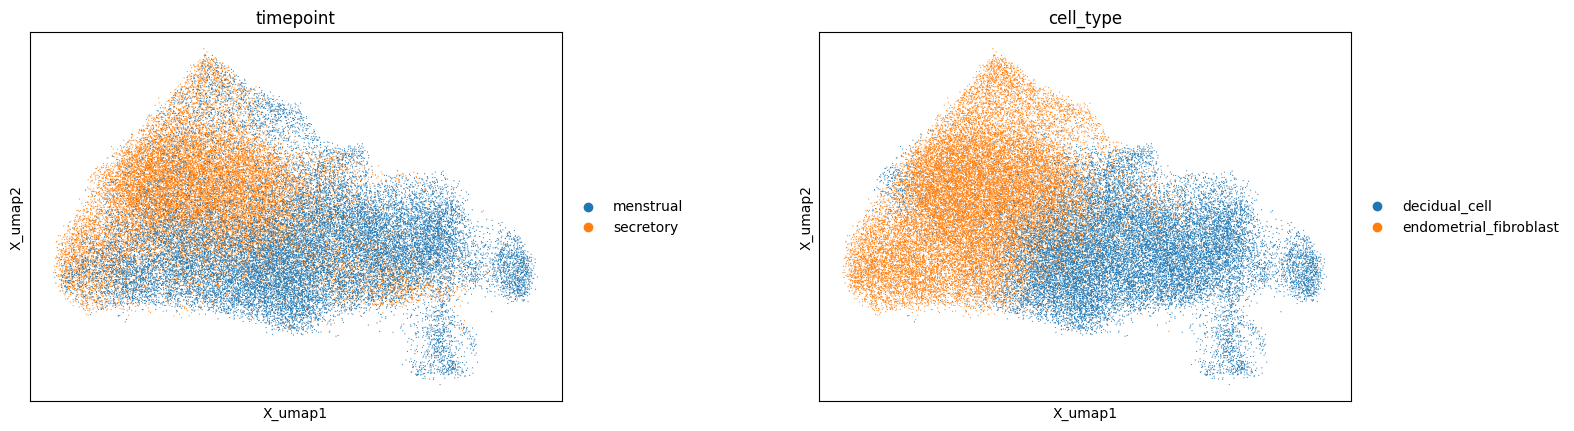

In [12]:
# basis="X_umap" EXPLICITLY — never X_umap_scVI
sc.pl.embedding(adata, basis="X_umap", color=["timepoint", "cell_type"],
                wspace=0.35, show=False)
savefig("umap_timepoint_celltype")
plt.show()

## moscot

In [15]:
from moscot.problems.time import TemporalProblem

tp_prob = TemporalProblem(adata)
tp_prob = tp_prob.score_genes_for_marginals(gene_set_proliferation="human",
                                            gene_set_apoptosis="human")
tp_prob = tp_prob.prepare(time_key="day", joint_attr="X_scVI")
tp_prob = tp_prob.solve(epsilon=1e-3, tau_a=0.95, tau_b=0.95, scale_cost="mean")
print("solved")

computing score 'proliferation'
    finished (0:00:01)
computing score 'apoptosis'
    finished (0:00:01)
INFO     Solving `1` problems                                                                                      
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(23441, 24092)].                                


E0828 23:57:08.721065 3232120 cuda_executor.cc:1206] [0] Failed to allocate device memory: INTERNAL: [0] Failed to allocate 32.92GiB (35344437760 bytes) of device memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0828 23:57:08.721468 3232120 cuda_executor.cc:1206] [0] Failed to allocate device memory: INTERNAL: [0] Failed to allocate 29.62GiB (31809992704 bytes) of device memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0828 23:57:08.721807 3232120 cuda_executor.cc:1206] [0] Failed to allocate device memory: INTERNAL: [0] Failed to allocate 26.66GiB (28628992000 bytes) of device memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0828 23:57:08.722132 3232120 cuda_executor.cc:1206] [0] Failed to allocate device memory: INTERNAL: [0] Failed to allocate 24.00GiB (25766092800 bytes) of device memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0828 23:57:08.722449 3232120 cuda_executor.cc:1206] [0] Failed to allocate device memory: INTERNAL: [0] Failed to allocate 21.60GiB (23189483520 by

solved


## RealTimeKernel — with the row-stochasticity repair

cellrank's setter rejects any matrix whose rows don't sum to 1 within `rtol=1e-12`, and the
stitched couplings leave a few all-zero rows. This is the workaround from cells 28–30 of the
original `realtime_informed_pseudotime_human.ipynb` — load-bearing, not diagnostic.

In [16]:
rtk = cr.kernels.RealTimeKernel.from_moscot(tp_prob)

try:
    rtk = rtk.compute_transition_matrix(self_transitions="all", conn_weight=0.2,
                                        threshold="auto")
    T = rtk.transition_matrix
    print("accepted the stitched matrix directly")

except ValueError as e:
    if "row stochastic" not in str(e):
        raise
    print(f"rejected: {e}\napplying the repair ...")

    T = (rtk._transition_matrix if getattr(rtk, "_transition_matrix", None) is not None
         else rtk._restich_couplings(rtk.couplings, self_transitions="all",
                                     conn_weight=0.2).X)
    T = csr_matrix(T).tocsr()

    rs = np.asarray(T.sum(axis=1)).ravel()
    dead = np.where(~np.isfinite(rs) | (rs == 0))[0]
    print(f"  dead rows: {len(dead)}")

    if len(dead):
        day_vals = adata.obs["day"].astype(float).to_numpy()
        T_lil = T.tolil()
        for i in dead:
            same = np.where(day_vals == day_vals[i])[0]
            T_lil.rows[i] = list(same)
            T_lil.data[i] = [1.0 / len(same)] * len(same)
        T = T_lil.tocsr()

    rs = np.asarray(T.sum(axis=1)).ravel()
    T = csr_matrix(T.multiply(1.0 / rs[:, None]))
    rtk.transition_matrix = T
    T = rtk.transition_matrix
    print("  repaired and assigned")

rs = np.asarray(T.sum(axis=1)).ravel()
print(f"\ntransition matrix {T.shape}  row sums [{rs.min():.9f}, {rs.max():.9f}]")
assert np.allclose(rs, 1.0, atol=1e-6)

  0%|          | 0/1 [00:00<?, ?time pair/s]

Using automatic `threshold=1.1046912294632898e-18`


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 36601 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 36601 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


accepted the stitched matrix directly

transition matrix (47533, 47533)  row sums [1.000000000, 1.000000000]


## DPT

In [17]:
def symmetrize(M):
    S = (M + M.T) / 2
    rs = S.sum(axis=1).A1
    S.data = S.data / rs[S.nonzero()[0]]
    return S

dpt = DPT(adata=adata, neighbors_key="neighbors")
dpt._transitions_sym = symmetrize(rtk.transition_matrix)
dpt.compute_eigen(n_comps=15, random_state=SEED)

adata.obsm["X_diffmap"] = dpt.eigen_basis
adata.uns["diffmap_evals"] = dpt.eigen_values
print("top eigenvalues:", np.round(dpt.eigen_values[:8], 5))

    eigenvalues of transition matrix
    [1.000004   0.9684997  0.95620775 0.9505486  0.937291   0.92411566
     0.9180819  0.9024665  0.88996094 0.8870748  0.87459815 0.8715418
     0.86479574 0.8618831  0.8550808 ]
top eigenvalues: [1.      0.9685  0.95621 0.95055 0.93729 0.92412 0.91808 0.90247]


### Root

No fine stromal subtype exists in human, so there is no `efib_proliferative` to anchor on.
The pool is the earliest-timepoint cells — 23,441 of them, half the dataset. Within that pool
we take the cell farthest from the centroid of the rest along DC2/DC3.

`ROOT_DIRECTION` is the knob: if ρ comes out negative, flip it to `"near"` and rerun from here.
Never negate `dpt_pseudotime` — downstream code assumes [0, 1].

In [18]:
ROOT_DIRECTION = "far"      # "far" = argmax | "near" = argmin

dc23 = adata.obsm["X_diffmap"][:, [2, 3]]
labels = adata.obs["cell_subtype"].astype(str)
ANCHOR = "efib_proliferative"

if ANCHOR in set(labels.unique()):
    root_mask = (labels == ANCHOR).values
    root_source = f"cell_subtype={ANCHOR}"
else:
    earliest = adata.obs["day"].astype(float).min()
    root_mask = (adata.obs["day"].astype(float) == earliest).values
    root_source = f"earliest day ({earliest}) — {ANCHOR!r} absent (expected for human)"
    print(f"NOTE: {ANCHOR!r} not present; using earliest-timepoint cells")

print(f"root source: {root_source}")
print(f"pool: {int(root_mask.sum()):,} cells")

centroid = dc23[~root_mask].mean(axis=0)
cand = np.where(root_mask)[0]
dists = np.linalg.norm(dc23[root_mask] - centroid, axis=1)
pick = dists.argmax() if ROOT_DIRECTION == "far" else dists.argmin()
root_idx = int(cand[pick])

print(f"root_direction={ROOT_DIRECTION!r}  dist={dists[pick]:.4f}  "
      f"pool range [{dists.min():.4f}, {dists.max():.4f}]")
print(f"root: {adata.obs_names[root_idx]}  timepoint={adata.obs['timepoint'].iloc[root_idx]}")

adata.uns["iroot"] = root_idx
sc.tl.dpt(adata)

pt = adata.obs["dpt_pseudotime"].to_numpy()
print(f"\npseudotime [{np.nanmin(pt):.4f}, {np.nanmax(pt):.4f}]  "
      f"non-finite={int((~np.isfinite(pt)).sum())}")

NOTE: 'efib_proliferative' not present; using earliest-timepoint cells
root source: earliest day (0.0) — 'efib_proliferative' absent (expected for human)
pool: 23,441 cells
root_direction='far'  dist=0.0298  pool range [0.0000, 0.0298]
root: GATGGAGTCGTCTCAC-1-secretory_mck6c  timepoint=secretory
computing Diffusion Pseudotime using n_dcs=10
    finished (0:00:00)

pseudotime [0.0000, 1.0000]  non-finite=0


root source: global DC2 max
root_direction='far'  DC2=0.004796  global range [-0.023782, 0.004796]
root: GTACAACGTTTGACAC-1-menstrual_mck5c  timepoint=menstrual  subtype=endometrial_fibroblast


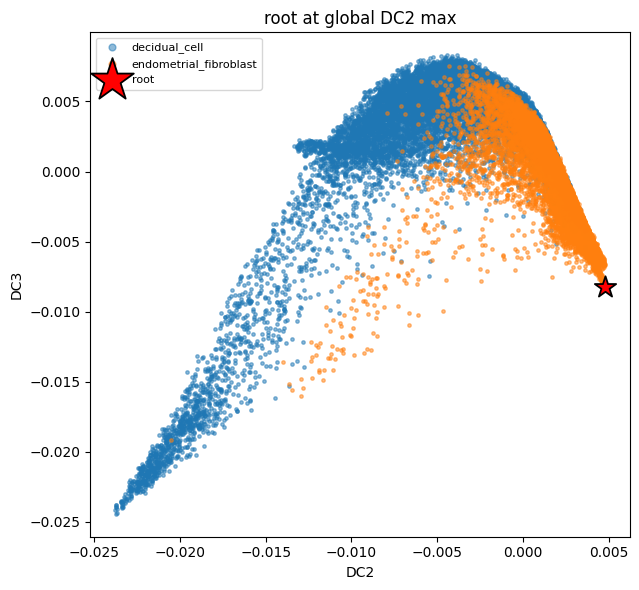

computing Diffusion Pseudotime using n_dcs=10
    finished (0:00:00)

pseudotime [0.0000, 1.0000]  non-finite=0
pseudotime at root (should be ~0): 0.000000


In [20]:
import numpy as np
import matplotlib.pyplot as plt

ROOT_DIRECTION = "far"      # "far" = max DC2 (argmax) | "near" = min DC2 (argmin)

# DC2, DC3 = columns 1, 2 of X_diffmap (column 0 is the trivial constant component).
dc23 = adata.obsm["X_diffmap"][:, [1, 2]]
dc2 = dc23[:, 0]
labels = adata.obs["cell_subtype"].astype(str)

# Global DC2 extreme — no cluster/day restriction.
root_idx = int(dc2.argmax() if ROOT_DIRECTION == "far" else dc2.argmin())
root_source = f"global DC2 {'max' if ROOT_DIRECTION == 'far' else 'min'}"

print(f"root source: {root_source}")
print(f"root_direction={ROOT_DIRECTION!r}  "
      f"DC2={dc2[root_idx]:.6f}  global range [{dc2.min():.6f}, {dc2.max():.6f}]")
print(f"root: {adata.obs_names[root_idx]}  "
      f"timepoint={adata.obs['timepoint'].iloc[root_idx]}  "
      f"subtype={labels.iloc[root_idx]}")

# ---- star plot on DC2/DC3 ----
fig, ax = plt.subplots(figsize=(6.5, 6))
for lab in sorted(labels.unique()):
    m = (labels == lab).values
    ax.scatter(dc23[m, 0], dc23[m, 1], s=6, alpha=0.5, label=lab)
ax.scatter(dc23[root_idx, 0], dc23[root_idx, 1],
           s=260, c="red", marker="*", edgecolor="black",
           linewidth=1.3, zorder=5, label="root")
ax.set_xlabel("DC2")
ax.set_ylabel("DC3")
ax.set_title(f"root at {root_source}")
ax.legend(markerscale=2, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

# ---- pseudotime ----
adata.uns["iroot"] = root_idx
sc.tl.dpt(adata)
pt = adata.obs["dpt_pseudotime"].to_numpy()
print(f"\npseudotime [{np.nanmin(pt):.4f}, {np.nanmax(pt):.4f}]  "
      f"non-finite={int((~np.isfinite(pt)).sum())}")
print(f"pseudotime at root (should be ~0): {pt[root_idx]:.6f}")

## Statistics

In [ ]:
day = adata.obs["day"].astype(float).to_numpy()
ok = np.isfinite(pt) & np.isfinite(day)

rho, p = spearmanr(pt[ok], day[ok])
print(f"Spearman(pt, day):  rho = {rho:+.4f}   p = {p:.3e}   n = {int(ok.sum()):,}")
print(f"orientation: {'OK' if rho > 0 else 'INVERTED -> set ROOT_DIRECTION=\'near\' and rerun'}")

print("\nby day:")
print(pd.DataFrame({"day": day[ok], "pt": pt[ok]})
      .groupby("day")["pt"].agg(["median", "mean", "std", "count"]).to_string())

print("\nby cell_type:")
print(adata.obs.groupby("cell_type", observed=True)["dpt_pseudotime"]
      .agg(["median", "mean", "std", "count"]).to_string())

print(f"\nREFERENCE — headless run 2026-08-28 gave rho = +0.0767 "
      f"(medians 0.4497 -> 0.4509).")
print("Mouse, for contrast: +0.6654 with 5 transitions and a real root anchor.")
print("A near-zero rho here is the expected structural result, not a bug.")

  saved pseudotime_human/v1_all_cells/figures/umap_pseudotime_day.pdf


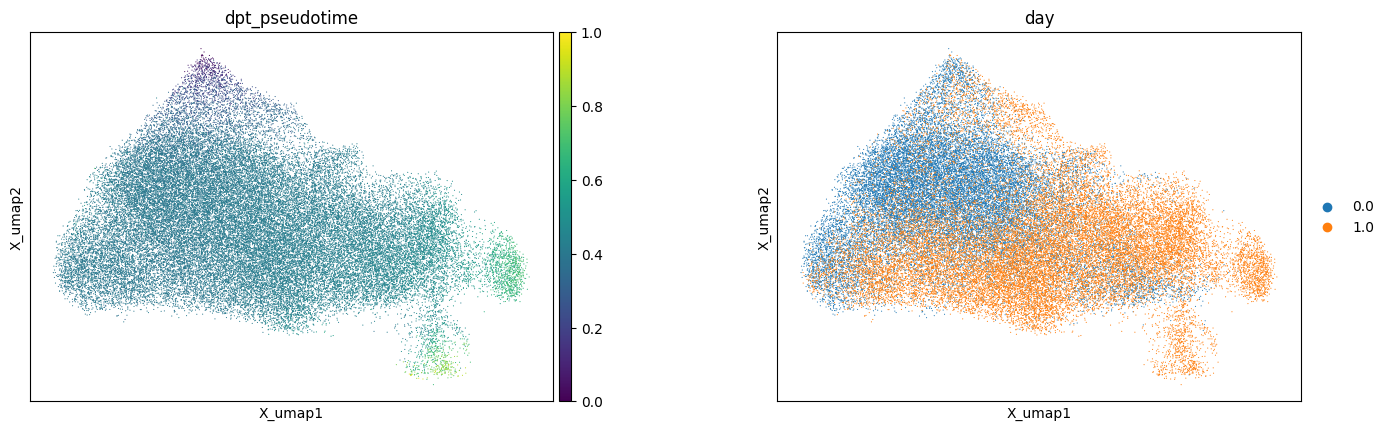

  saved pseudotime_human/v1_all_cells/figures/diffmap_pseudotime_day.pdf


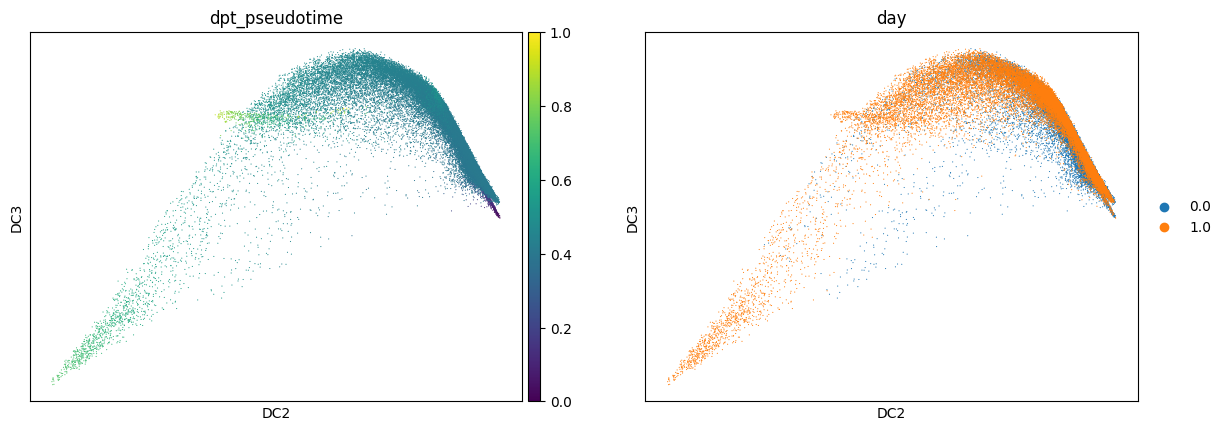

In [21]:
sc.pl.embedding(adata, basis="X_umap", color=["dpt_pseudotime", "day"],
                wspace=0.3, cmap="viridis", show=False)
savefig("umap_pseudotime_day")
plt.show()

sc.pl.diffmap(adata, color=["dpt_pseudotime", "day"], components="2,3",
              cmap="viridis", show=False)
savefig("diffmap_pseudotime_day")
plt.show()

2026-08-29 00:01:37 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-29 00:01:37 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


  saved pseudotime_human/v1_all_cells/figures/violin_pseudotime_by_day.pdf


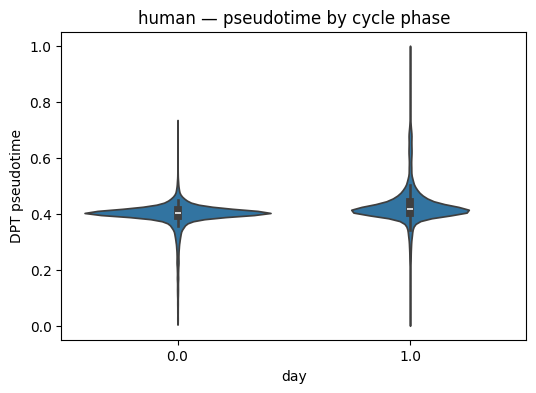

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(x=adata.obs["day"].astype(float).astype(str),
               y=adata.obs["dpt_pseudotime"], ax=ax, cut=0)
ax.set_xlabel("day"); ax.set_ylabel("DPT pseudotime")
ax.set_title("human — pseudotime by cycle phase")
savefig("violin_pseudotime_by_day")
plt.show()

## Spatial — per sample, never pooled

cells with coordinates: 33,250 / 47,533 (70.0%)
  saved pseudotime_human/v1_all_cells/figures/spatial_pseudotime_by_sample.pdf


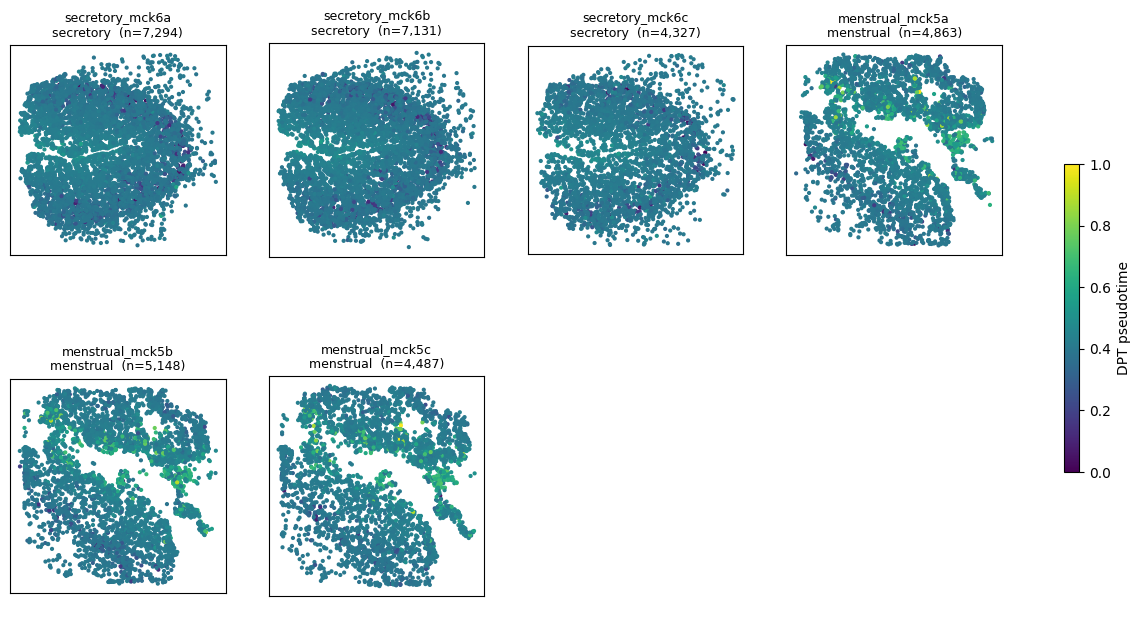

In [23]:
has_xy = adata.obs[["x_um_dbscan", "y_um_dbscan"]].notna().all(axis=1).values
print(f"cells with coordinates: {has_xy.sum():,} / {adata.n_obs:,} ({100*has_xy.mean():.1f}%)")

samples = [s for s in adata.obs["sample"].astype(str).unique()
           if has_xy[(adata.obs["sample"].astype(str) == s).values].sum() > 0]

ncol = 4; nrow = int(np.ceil(len(samples) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4*ncol, 4*nrow), squeeze=False)
for ax, s in zip(axes.ravel(), samples):
    m = (adata.obs["sample"].astype(str) == s).values & has_xy
    sub = adata.obs.loc[m]
    h = ax.scatter(sub["x_um_dbscan"], sub["y_um_dbscan"], c=sub["dpt_pseudotime"],
                   cmap="viridis", s=4, vmin=0, vmax=1)
    ax.set_title(f"{s}\n{sub['timepoint'].iloc[0]}  (n={m.sum():,})", fontsize=9)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
for ax in axes.ravel()[len(samples):]:
    ax.axis("off")
fig.colorbar(h, ax=axes, shrink=0.5, label="DPT pseudotime")
savefig("spatial_pseudotime_by_sample")
plt.show()

## Save

In [24]:
out_h5ad = RES / f"{DATE}_human_fibdec_pseudotime.h5ad"
tmp = out_h5ad.with_suffix(".h5ad.tmp")
adata.write_h5ad(tmp)
os.replace(tmp, out_h5ad)
print(f"wrote {out_h5ad}")

cols = [c for c in ["sample","timepoint","day","cell_type","cell_subtype",
                    "dpt_pseudotime","x_um_dbscan","y_um_dbscan"] if c in adata.obs.columns]
adata.obs[cols].to_csv(RES / "human_pseudotime_obs.csv")

summary = {
    "species": "human", "variant": VARIANT, "input": str(ADATA_PATH),
    "n_cells": int(adata.n_obs),
    "n_transitions": int(len(adata.obs["day"].cat.categories) - 1),
    "scvi_source": "04b latent_human_stromal.h5ad (stromal lineage fit)",
    "umap_source": "computed in THIS notebook on the 47,533 fib/dec cells",
    "carried_embeddings_purged": CARRIED,
    "root_source": root_source, "root_direction": ROOT_DIRECTION,
    "root_obs_name": str(adata.obs_names[root_idx]),
    "spearman_rho_day": float(rho), "spearman_p": float(p),
    "orientation_ok": bool(rho > 0),
    "cells_with_coords": int(has_xy.sum()),
}
(RES / "human_pseudotime_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

wrote pseudotime_human/v1_all_cells/results/2026_08_28_human_fibdec_pseudotime.h5ad


NameError: name 'rho' is not defined

---

## Running

```bash
salloc -p gpu --gres=gpu:1 -t 0-04:00 --mem=96G
export XDG_CACHE_HOME=/n/lab_storage/eddy_lab/users/nhilgert/.cache_scratch
export NUMBA_CACHE_DIR=$XDG_CACHE_HOME/numba
export MPLCONFIGDIR=$XDG_CACHE_HOME/mpl
export TMPDIR=/n/lab_storage/eddy_lab/users/nhilgert/tmp
```

Kernel: `Python (rsc_uv)`. **Run every cell in order** — skipping the UMAP cell is what
produced the bad plot last time.

If ρ comes out negative, set `ROOT_DIRECTION = "near"` and rerun from the root cell down.